# 05 — Classification sub-analysis (Week 12)

Our main study (notebook 04) predicts a **number** (next-day sales), so it uses
regression. This short notebook demonstrates the **Week 12 classification** toolkit on
the same data by turning the problem into a yes/no question:

> **Will tomorrow be a "high-sales" day for this product?**  (high = next-day
> `sale_amount` above the training-set median)

**Classification** (Week 12) assigns each case to a discrete class. We use two Week 12
algorithms — **Logistic Regression** and a **Random Forest classifier** — against a
**majority-class baseline**, and we judge them with the **confusion matrix** and the
metrics built on it:

| Term | Meaning |
| --- | --- |
| TP / TN | correctly predicted high / low days |
| FP (Type I error) | predicted high, was low |
| FN (Type II error) | predicted low, was high |
| Accuracy | (TP+TN) / all |
| Precision | of predicted-high days, how many were truly high |
| Recall | of truly-high days, how many we caught |
| ROC-AUC | ranking quality across all thresholds (0.5 = random, 1.0 = perfect) |

The predictors are the **same no-leakage features** as notebook 04 (past-sales lags,
planned promotion/holiday/discount, lagged weather & stockout).

In [ ]:
# --- run from anywhere: switch to the data-prep folder so relative paths resolve ---
# (notebooks live here, but the shared data/subset and Data/ folders are under
#  'Data Prep - Derrick'; this makes data/subset/..., ../Data/..., outputs/... all work.)
import os
from pathlib import Path
_cwd = Path.cwd().resolve()
_root = next((p for p in (_cwd, *_cwd.parents) if (p / 'Data Prep - Derrick').is_dir()), None)
if _root is not None:
    os.chdir(_root / 'Data Prep - Derrick')
print('working dir:', os.getcwd())

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, confusion_matrix)

os.makedirs("outputs/models", exist_ok=True)
df = pd.read_csv("data/subset/freshretail_subset_daily.csv", parse_dates=["dt"])
df = df.sort_values(["store_id", "product_id", "dt"]).reset_index(drop=True)
print(f"loaded {len(df)} rows")

loaded 9000 rows


## 1) Features and the binary label

Same features as notebook 04, built per series so no future information leaks. The
label is created from a **training-set** median threshold, so the test set never
influences the class definition.

In [2]:
g = df.groupby(["store_id", "product_id"], observed=True)
df["lag_1"] = g["sale_amount"].shift(1)
df["lag_7"] = g["sale_amount"].shift(7)
df["roll7"] = g["sale_amount"].transform(lambda s: s.shift(1).rolling(7).mean())
for col in ["precpt", "avg_temperature", "avg_humidity", "avg_wind_level", "stock_hour6_22_cnt"]:
    df[col + "_lag1"] = g[col].shift(1)
df["dow"] = df["dt"].dt.dayofweek

features = ["lag_1", "lag_7", "roll7", "discount", "holiday_flag", "activity_flag", "dow",
            "precpt_lag1", "avg_temperature_lag1", "avg_humidity_lag1",
            "avg_wind_level_lag1", "stock_hour6_22_cnt_lag1"]

model_df = df.dropna(subset=features + ["sale_amount"]).copy()

# chronological split (same cut points as notebook 04)
dates = np.sort(model_df["dt"].unique())
train = model_df[model_df["dt"] <= dates[int(len(dates) * 0.75)]].copy()
test = model_df[model_df["dt"] > dates[int(len(dates) * 0.85)]].copy()

# binary label from the TRAIN median only (no leakage)
threshold = train["sale_amount"].median()
y_train = (train["sale_amount"] > threshold).astype(int)
y_test = (test["sale_amount"] > threshold).astype(int)
X_train, X_test = train[features], test[features]

print(f"high-day threshold (train median sale_amount): {threshold:.2f}")
print(f"train rows {len(train)}, test rows {len(test)} | test high-day rate: {y_test.mean():.3f}")

high-day threshold (train median sale_amount): 0.70
train rows 6300, test rows 1200 | test high-day rate: 0.562


## 2) Majority-class baseline

A classifier is only useful if it beats always-guessing the most common class.

In [3]:
majority_class = int(y_train.mean() > 0.5)
base_acc = accuracy_score(y_test, np.full(len(y_test), majority_class))
print(f"majority class = {majority_class}  ->  baseline accuracy {base_acc:.3f}")

majority class = 0  ->  baseline accuracy 0.438


## 3) Logistic Regression (Week 12)

Logistic regression maps a linear combination of predictors to a probability via the
logit function, then thresholds it to a class. Features are standardized (fit on train
only).

In [4]:
logit = Pipeline([("scaler", StandardScaler()),
                  ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
logit_pred = logit.predict(X_test)
logit_proba = logit.predict_proba(X_test)[:, 1]
print("logistic regression:")
print(f"  accuracy {accuracy_score(y_test, logit_pred):.3f} | precision {precision_score(y_test, logit_pred):.3f}"
      f" | recall {recall_score(y_test, logit_pred):.3f} | ROC-AUC {roc_auc_score(y_test, logit_proba):.3f}")
print("  confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, logit_pred))

logistic regression:
  accuracy 0.787 | precision 0.819 | recall 0.799 | ROC-AUC 0.869
  confusion matrix [[TN, FP], [FN, TP]]:
[[406 119]
 [136 539]]


## 4) Random Forest classifier (Week 12 ensemble)

The same ensemble idea as notebook 04, but voting for a class instead of averaging a
number.

In [5]:
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=4, n_jobs=-1)
rf_clf.fit(X_train, y_train)
rf_pred = rf_clf.predict(X_test)
rf_proba = rf_clf.predict_proba(X_test)[:, 1]
print("random forest classifier:")
print(f"  accuracy {accuracy_score(y_test, rf_pred):.3f} | precision {precision_score(y_test, rf_pred):.3f}"
      f" | recall {recall_score(y_test, rf_pred):.3f} | ROC-AUC {roc_auc_score(y_test, rf_proba):.3f}")
print("  confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, rf_pred))

random forest classifier:
  accuracy 0.782 | precision 0.829 | recall 0.773 | ROC-AUC 0.870
  confusion matrix [[TN, FP], [FN, TP]]:
[[417 108]
 [153 522]]


## 5) Results — metrics table, ROC curve, confusion matrix

                     accuracy  precision  recall  ROC-AUC
majority baseline       0.438        NaN     NaN      NaN
logistic regression     0.788      0.819   0.799    0.869
random forest           0.782      0.829   0.773    0.870


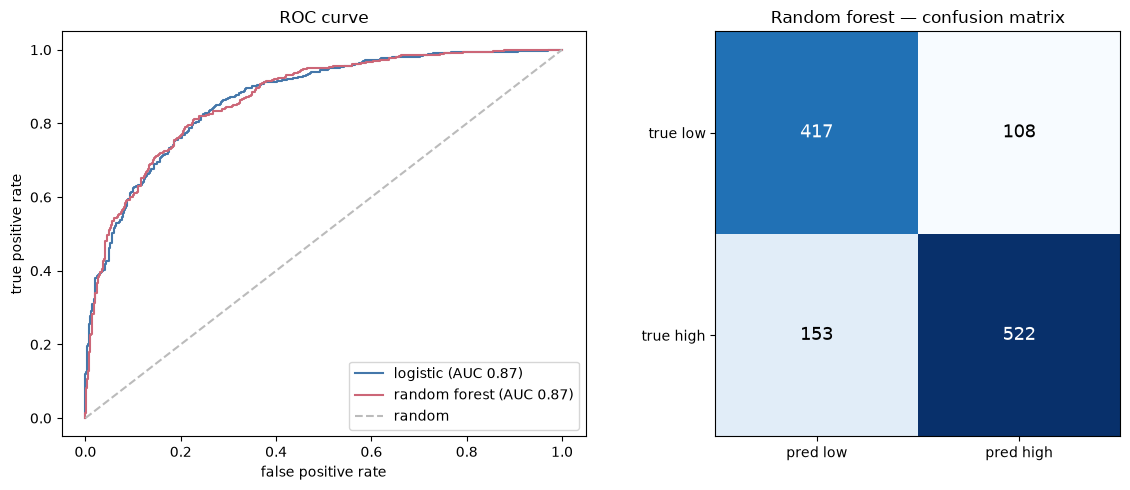


saved outputs/models/09_classification.png


In [6]:
# metrics table
def row(y, pred, proba):
    return [accuracy_score(y, pred), precision_score(y, pred), recall_score(y, pred), roc_auc_score(y, proba)]

clf_results = pd.DataFrame(
    [[base_acc, np.nan, np.nan, np.nan],
     row(y_test, logit_pred, logit_proba),
     row(y_test, rf_pred, rf_proba)],
    columns=["accuracy", "precision", "recall", "ROC-AUC"],
    index=["majority baseline", "logistic regression", "random forest"],
).round(3)
print(clf_results.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curves
for name, proba, color in [("logistic", logit_proba, "#4477aa"), ("random forest", rf_proba, "#cc6677")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, proba):.2f})")
axes[0].plot([0, 1], [0, 1], "--", color="#bbbbbb", label="random")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curve"); axes[0].legend()

# confusion matrix for the random forest
cm = confusion_matrix(y_test, rf_pred)
axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["pred low", "pred high"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["true low", "true high"])
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
axes[1].set_title("Random forest \u2014 confusion matrix")

plt.tight_layout(); plt.savefig("outputs/models/09_classification.png", dpi=150); 
plt.show()
print("\nsaved outputs/models/09_classification.png")

## 6) Interpretation and limitations

- **Both classifiers clearly beat the majority baseline** (accuracy ~0.44), reaching
  about **0.79 accuracy and ROC-AUC ~0.87** — the same advance information that helped
  the regression also separates high- from low-sales days well.
- **Reading the confusion matrix (Week 12):** precision ~0.82 means most days we *flag*
  as high really are high (few false positives / Type I errors); recall ~0.77–0.80
  means we *catch* most truly-high days (moderate false negatives / Type II errors). For
  inventory, missing a high day (FN) usually costs more than a false alarm (FP), so one
  could lower the decision threshold to raise recall at the expense of precision.
- **Logistic vs forest:** essentially tied here; logistic is more interpretable (log-odds
  coefficients), the forest captures interactions — the Week 12 "no single best
  algorithm" point.

**Why this is a side analysis, not the main model.** Binarizing throws away information
(a day just above vs far above the median look identical), so for a sales *forecast* the
regression in notebook 04 is the right tool. This notebook exists to demonstrate the
Week 12 classification workflow — confusion matrix, precision/recall, ROC-AUC — on an
operational "high-demand day" question.

**Limitations** carry over from the main study: observed (not unmet) demand, a 90-day
window, and a 100-series convenience sample.